# Notebook 08 — Environmental Anomaly Detection

**Project:** RiskWeave — climate-informed dengue risk forecasting and inspection planning for Sri Lanka.

## Purpose
Identify unusual weekly environmental conditions within each district using historical weather variables in the processed dengue-weather dataset.

Environmental anomaly scores use weather variables only. Dengue cases are not used to calculate these scores.

## Method
- District-specific trailing historical baselines.
- Exclude the current period from its baseline (`shift(1)`) to prevent look-ahead leakage.
- Rolling median and median absolute deviation (MAD).
- Separate robust scores for each weather variable.
- Screen both unusually high and unusually low values.
- The score threshold is provisional, not an official environmental or dengue outbreak threshold.

**Data-source note:** The historical weather data currently used in RiskWeave is Open-Meteo ERA5, not NASA POWER. Document this as a data-source deviation from the proposal.

An environmental anomaly is an unusual weather observation relative to that district's history. It does not establish increased dengue transmission, predict an outbreak, or confirm an outbreak.

## 1. Imports and settings

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

ROLLING_WINDOW = 52
MIN_BASELINE_OBSERVATIONS = 26
PROVISIONAL_ABS_SCORE_THRESHOLD = 3.5

print("Libraries loaded.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Libraries loaded.
Pandas: 2.3.3
NumPy: 2.3.4


## 2. Resolve project paths and load the processed dataset

In [2]:
cwd = Path.cwd()

if cwd.name.lower() == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "data").exists():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(
        "Could not identify RiskWeave project root. "
        "Open this notebook from the project notebooks folder or project root."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dengue_weather_weekly_25_districts.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "environmental_anomaly_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Processed dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
df["week_start"] = pd.to_datetime(df["week_start"], errors="coerce")
df["week_end"] = pd.to_datetime(df["week_end"], errors="coerce")

print("Dataset loaded.")
print("Project root:", PROJECT_ROOT)
print("Input:", DATA_PATH)
print("Output:", OUTPUT_DIR)
print("Shape:", df.shape)
print("Districts:", df["district_key"].nunique())
print("Date range:", df["week_start"].min(), "to", df["week_start"].max())
display(df.head())

Dataset loaded.
Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Input: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\dengue_weather_weekly_25_districts.csv
Output: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\environmental_anomaly_detection
Shape: (24775, 27)
Districts: 25
Date range: 2006-12-23 00:00:00 to 2025-12-13 00:00:00


,district_key,week_start,week_end,dengue_cases,reporting_period_days,source_reporting_rows,source_areas,weather_days_observed,weather_days_expected,weather_days_complete,precipitation_sum,precipitation_hours,shortwave_radiation_sum,et0_fao_evapotranspiration,precipitation_mean_daily,shortwave_radiation_mean_daily,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,wind_direction_10m_dominant
0,ampara,2006-12-23,2006-12-29,0,7,2,Ampara | Kalmune,7,7,True,15.3,60.0,97.86,23.42,2.185714,13.980000,25.342857,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,8.574025
1,ampara,2006-12-30,2007-01-05,0,7,2,Ampara | Kalmune,7,7,True,0.0,0.0,142.30,32.75,0.000000,20.328571,24.600000,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,358.285579
2,ampara,2007-01-06,2007-01-12,0,7,2,Ampara | Kalmune,7,7,True,77.2,115.0,90.53,19.61,11.028571,12.932857,24.885714,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,20.694632
3,ampara,2007-01-13,2007-01-19,0,7,2,Ampara | Kalmune,7,7,True,7.3,33.0,118.19,25.32,1.042857,16.884286,25.514286,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,11.275426
4,ampara,2007-01-20,2007-01-26,0,7,2,Ampara | Kalmune,7,7,True,30.1,28.0,119.23,27.83,4.300000,17.032857,25.085714,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,7.286656


## 3. Data-quality checks

In [3]:
required_columns = ["district_key", "week_start", "week_end"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

quality_report = {
    "rows": len(df),
    "districts": df["district_key"].nunique(),
    "missing_district": df["district_key"].isna().sum(),
    "missing_week_start": df["week_start"].isna().sum(),
    "missing_week_end": df["week_end"].isna().sum(),
    "duplicate_district_week_start": df.duplicated(["district_key", "week_start"]).sum(),
    "week_end_before_week_start": (df["week_end"] < df["week_start"]).sum(),
}
display(pd.Series(quality_report, name="value"))

if any(quality_report[k] > 0 for k in [
    "missing_district", "missing_week_start", "missing_week_end",
    "duplicate_district_week_start", "week_end_before_week_start"
]):
    raise ValueError("Resolve data-quality issues before continuing.")

print("Identifier and date checks passed.")

rows                             24775
districts                           25
missing_district                     0
missing_week_start                   0
missing_week_end                     0
duplicate_district_week_start        0
week_end_before_week_start           0
Name: value, dtype: int64

Identifier and date checks passed.


## 4. Select available environmental variables

Only columns present in the dataset will be used. Review any missing expected columns rather than assuming they exist.

In [4]:
candidate_weather_features = [
    "precipitation_mean_daily",
    "precipitation_hours",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "cloud_cover_mean",
    "shortwave_radiation_mean_daily",
    "et0_fao_evapotranspiration",
]

weather_features = [c for c in candidate_weather_features if c in df.columns]
missing_weather_features = [c for c in candidate_weather_features if c not in df.columns]

print("Available weather features:")
for feature in weather_features:
    print("-", feature)

print("\nExpected weather features not found:")
for feature in missing_weather_features:
    print("-", feature)

if not weather_features:
    raise ValueError(
        "None of the expected weather columns were found. "
        "Inspect df.columns and update candidate_weather_features."
    )

print(f"Using {len(weather_features)} weather features.")

Available weather features:
- precipitation_mean_daily
- precipitation_hours
- temperature_2m_mean
- temperature_2m_max
- temperature_2m_min
- relative_humidity_2m_mean
- relative_humidity_2m_max
- relative_humidity_2m_min
- dew_point_2m_mean
- wind_speed_10m_mean
- wind_speed_10m_max
- cloud_cover_mean
- shortwave_radiation_mean_daily
- et0_fao_evapotranspiration

Expected weather features not found:
Using 14 weather features.


## 5. Inspect weather-variable completeness and distributions

Missing or non-numeric weather values are not silently imputed.

In [5]:
for feature in weather_features:
    df[feature] = pd.to_numeric(df[feature], errors="coerce")

weather_quality = pd.DataFrame({
    "feature": weather_features,
    "missing_count": [int(df[c].isna().sum()) for c in weather_features],
    "missing_percent": [float(df[c].isna().mean() * 100) for c in weather_features],
    "minimum": [df[c].min() for c in weather_features],
    "median": [df[c].median() for c in weather_features],
    "maximum": [df[c].max() for c in weather_features],
})
display(weather_quality.sort_values("missing_percent", ascending=False))

,feature,missing_count,missing_percent,minimum,median,maximum
0,precipitation_mean_daily,0,0.0,0.000000,3.000000,84.600000
1,precipitation_hours,0,0.0,0.000000,40.000000,168.000000
2,temperature_2m_mean,0,0.0,10.485714,26.614286,32.028571
3,temperature_2m_max,0,0.0,12.757143,30.214286,38.457143
4,temperature_2m_min,0,0.0,5.657143,24.000000,29.785714
5,relative_humidity_2m_mean,0,0.0,52.428571,82.142857,97.571429
6,relative_humidity_2m_max,0,0.0,65.142857,93.571429,100.000000
7,relative_humidity_2m_min,0,0.0,22.142857,66.142857,92.142857
8,dew_point_2m_mean,0,0.0,3.785714,23.214286,26.914286
9,wind_speed_10m_mean,0,0.0,1.742857,9.400000,39.271429


## 6. Sort records and create calendar fields

In [6]:
df = df.sort_values(["district_key", "week_start"]).reset_index(drop=True)
df["year"] = df["week_start"].dt.year
df["week_of_year"] = df["week_start"].dt.isocalendar().week.astype("Int64")

print("Chronological sorting completed.")
display(df[["district_key", "week_start", "week_of_year"] + weather_features].head())

Chronological sorting completed.


,district_key,week_start,week_of_year,precipitation_mean_daily,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,relative_humidity_2m_max,relative_humidity_2m_min,dew_point_2m_mean,wind_speed_10m_mean,wind_speed_10m_max,cloud_cover_mean,shortwave_radiation_mean_daily,et0_fao_evapotranspiration
0,ampara,2006-12-23,51,2.185714,60.0,25.342857,27.528571,23.571429,79.857143,87.285714,70.571429,21.471429,15.685714,21.085714,89.142857,13.980000,23.42
1,ampara,2006-12-30,52,0.000000,0.0,24.600000,28.042857,21.385714,71.142857,82.428571,57.000000,18.885714,14.485714,19.614286,59.428571,20.328571,32.75
2,ampara,2007-01-06,1,11.028571,115.0,24.885714,26.957143,23.271429,86.285714,92.285714,78.714286,22.285714,14.842857,18.828571,78.285714,12.932857,19.61
3,ampara,2007-01-13,2,1.042857,33.0,25.514286,27.728571,23.571429,83.142857,89.714286,74.571429,22.357143,17.114286,23.000000,77.857143,16.884286,25.32
4,ampara,2007-01-20,3,4.300000,28.0,25.085714,27.814286,22.742857,76.714286,85.142857,66.142857,20.600000,15.514286,20.385714,71.142857,17.032857,27.83


## 7. Calculate district-specific trailing robust baselines

For each district and weather variable:
- Baseline uses up to the previous 52 reporting periods.
- Current period is excluded using `shift(1)`.
- At least 26 previous non-missing values are required.
- MAD is the median absolute deviation from the rolling median.

A zero MAD is not replaced with an arbitrary constant. Scores for zero-MAD baselines remain unavailable.

In [15]:

# Section 7 — Corrected district-specific robust baselines

scored_parts = []

for feature in weather_features:

    temp = df[
        ["district_key", "week_start", "week_end", feature]
    ].copy()

    temp = temp.sort_values(
        ["district_key", "week_start"]
    ).reset_index(drop=True)

    # Exclude the current observation from its historical baseline.
    historical = (
        temp.groupby("district_key")[feature]
        .shift(1)
    )

    # Calculate the rolling historical median.
    baseline_median = (
        historical.groupby(temp["district_key"])
        .transform(
            lambda s: s.rolling(
                window=ROLLING_WINDOW,
                min_periods=MIN_BASELINE_OBSERVATIONS
            ).median()
        )
    )

    # Calculate MAD using the SAME historical window.
    # MAD = median(abs(x - median(x)))
    def calculate_mad(values):
        values = np.asarray(values)
        window_median = np.median(values)
        return np.median(np.abs(values - window_median))

    baseline_mad = (
        historical.groupby(temp["district_key"])
        .transform(
            lambda s: s.rolling(
                window=ROLLING_WINDOW,
                min_periods=MIN_BASELINE_OBSERVATIONS
            ).apply(calculate_mad, raw=True)
        )
    )

    denominator = 1.4826 * baseline_mad

    robust_score = np.where(
        denominator > 0,
        (temp[feature] - baseline_median) / denominator,
        np.nan
    )

    temp[f"{feature}_baseline_median"] = baseline_median
    temp[f"{feature}_baseline_mad"] = baseline_mad
    temp[f"{feature}_robust_score"] = robust_score

    scored_parts.append(
        temp[
            [
                "district_key",
                "week_start",
                "week_end",
                feature,
                f"{feature}_baseline_median",
                f"{feature}_baseline_mad",
                f"{feature}_robust_score"
            ]
        ]
    )

print("Corrected robust baselines and scores calculated.")


Corrected robust baselines and scores calculated.


In [16]:
# Verify corrected MAD values for all weather features

for feature, part in zip(weather_features, scored_parts):

    mad_col = f"{feature}_baseline_mad"
    score_col = f"{feature}_robust_score"

    print(f"\n--- {feature} ---")

    print("Minimum MAD:", part[mad_col].min())
    print("Negative MAD count:", (part[mad_col] < 0).sum())
    print("Zero MAD count:", (part[mad_col] == 0).sum())
    print("Valid robust scores:", part[score_col].notna().sum())

    display(
        part[
            [
                "district_key",
                "week_start",
                feature,
                mad_col,
                score_col
            ]
        ].tail(3)
    )


--- precipitation_mean_daily ---
Minimum MAD: 0.18571428571428567
Negative MAD count: 0
Zero MAD count: 0
Valid robust scores: 23475


,district_key,week_start,precipitation_mean_daily,precipitation_mean_daily_baseline_mad,precipitation_mean_daily_robust_score
24772,vavuniya,2025-11-29,4.028571,1.285714,1.251555
24773,vavuniya,2025-12-06,9.842857,1.485714,3.573504
24774,vavuniya,2025-12-13,3.200000,1.485714,0.557752



--- precipitation_hours ---
Minimum MAD: 4.5
Negative MAD count: 0
Zero MAD count: 0
Valid robust scores: 23475


,district_key,week_start,precipitation_hours,precipitation_hours_baseline_mad,precipitation_hours_robust_score
24772,vavuniya,2025-11-29,65.0,17.0,1.329144
24773,vavuniya,2025-12-06,97.0,18.0,2.454397
24774,vavuniya,2025-12-13,81.0,18.0,1.854850



--- temperature_2m_mean ---
Minimum MAD: 0.22857142857142776
Negative MAD count: 0
Zero MAD count: 0
Valid robust scores: 23475


,district_key,week_start,temperature_2m_mean,temperature_2m_mean_baseline_mad,temperature_2m_mean_robust_score
24772,vavuniya,2025-11-29,25.828571,1.521429,-1.082985
24773,vavuniya,2025-12-06,25.357143,1.542857,-1.274038
24774,vavuniya,2025-12-13,25.171429,1.542857,-1.355227


... (18 outputs left out)


--- shortwave_radiation_mean_daily ---
Minimum MAD: 0.9971428571428564
Negative MAD count: 0
Zero MAD count: 0
Valid robust scores: 23475


,district_key,week_start,shortwave_radiation_mean_daily,shortwave_radiation_mean_daily_baseline_mad,shortwave_radiation_mean_daily_robust_score
24772,vavuniya,2025-11-29,14.758571,2.074286,-1.630019
24773,vavuniya,2025-12-06,11.387143,2.074286,-2.726299
24774,vavuniya,2025-12-13,13.158571,2.074286,-2.150288



--- et0_fao_evapotranspiration ---
Minimum MAD: 1.584999999999999
Negative MAD count: 0
Zero MAD count: 0
Valid robust scores: 23475


,district_key,week_start,et0_fao_evapotranspiration,et0_fao_evapotranspiration_baseline_mad,et0_fao_evapotranspiration_robust_score
24772,vavuniya,2025-11-29,21.45,6.98,-1.010287
24773,vavuniya,2025-12-06,16.90,7.21,-1.403708
24774,vavuniya,2025-12-13,18.86,7.21,-1.220351


## 8. Reshape scores into a long-format table

Each row represents one district, reporting period and weather feature. Different weather variables retain their own units and scores.

In [17]:
long_parts = []

for feature, part in zip(weather_features, scored_parts):
    feature_part = part.rename(columns={
        feature: "observed_value",
        f"{feature}_baseline_median": "baseline_median",
        f"{feature}_baseline_mad": "baseline_mad",
        f"{feature}_robust_score": "robust_score",
    }).copy()
    feature_part["weather_feature"] = feature
    long_parts.append(feature_part)

environmental_scores = pd.concat(long_parts, ignore_index=True)

environmental_scores["anomaly_status"] = np.select(
    [
        environmental_scores["robust_score"].isna(),
        environmental_scores["robust_score"] >= PROVISIONAL_ABS_SCORE_THRESHOLD,
        environmental_scores["robust_score"] <= -PROVISIONAL_ABS_SCORE_THRESHOLD,
    ],
    [
        "insufficient_or_zero_mad_baseline",
        "candidate_high_environmental_anomaly",
        "candidate_low_environmental_anomaly",
    ],
    default="not_flagged"
)

print("Environmental score table shape:", environmental_scores.shape)
display(environmental_scores.head(10))

Environmental score table shape: (346850, 9)


,district_key,week_start,week_end,observed_value,baseline_median,baseline_mad,robust_score,weather_feature,anomaly_status
0,ampara,2006-12-23,2006-12-29,2.185714,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
1,ampara,2006-12-30,2007-01-05,0.000000,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
2,ampara,2007-01-06,2007-01-12,11.028571,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
3,ampara,2007-01-13,2007-01-19,1.042857,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
4,ampara,2007-01-20,2007-01-26,4.300000,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
5,ampara,2007-01-27,2007-02-02,4.828571,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
6,ampara,2007-02-03,2007-02-09,0.471429,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
7,ampara,2007-02-10,2007-02-16,1.157143,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
8,ampara,2007-02-17,2007-02-23,0.100000,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline
9,ampara,2007-02-24,2007-03-02,1.642857,NaN,NaN,NaN,precipitation_mean_daily,insufficient_or_zero_mad_baseline


In [19]:
# Section 8 — Validation checks

print("Total rows:", len(environmental_scores))

print("\nWeather features:")
print(environmental_scores["weather_feature"].nunique())

print("\nDistricts:")
print(environmental_scores["district_key"].nunique())

print("\nMissing robust scores:")
print(environmental_scores["robust_score"].isna().sum())

print("\nAnomaly status counts:")
print(environmental_scores["anomaly_status"].value_counts(dropna=False))

print("\nDuplicate district-week-feature combinations:")
print(
    environmental_scores.duplicated(
        subset=["district_key", "week_start", "weather_feature"]
    ).sum()
)

Total rows: 346850

Weather features:
14

Districts:
25

Missing robust scores:
18200

Anomaly status counts:
anomaly_status
not_flagged                             321946
insufficient_or_zero_mad_baseline        18200
candidate_high_environmental_anomaly      3666
candidate_low_environmental_anomaly       3038
Name: count, dtype: int64

Duplicate district-week-feature combinations:
0


## 9. Review score coverage and candidate counts

The provisional absolute score threshold screens both unusually high and unusually low weather values. It is not an official warning threshold.

In [21]:
status_counts = (
    environmental_scores["anomaly_status"]
    .value_counts(dropna=False)
    .rename_axis("anomaly_status")
    .reset_index(name="observations")
)
display(status_counts)

feature_status_counts = (
    environmental_scores.groupby(["weather_feature", "anomaly_status"])
    .size().unstack(fill_value=0)
)
display(feature_status_counts)

,anomaly_status,observations
0,not_flagged,321946
1,insufficient_or_zero_mad_baseline,18200
2,candidate_high_environmental_anomaly,3666
3,candidate_low_environmental_anomaly,3038


anomaly_status,candidate_high_environmental_anomaly,candidate_low_environmental_anomaly,insufficient_or_zero_mad_baseline,not_flagged
weather_feature,,,,
cloud_cover_mean,0,218,1300,23257
dew_point_2m_mean,10,753,1300,22712
et0_fao_evapotranspiration,2,86,1300,23387
precipitation_hours,822,0,1300,22653
precipitation_mean_daily,2339,0,1300,21136
relative_humidity_2m_max,8,703,1300,22764
relative_humidity_2m_mean,12,562,1300,22901
relative_humidity_2m_min,33,329,1300,23113
shortwave_radiation_mean_daily,0,271,1300,23204


In [22]:
# Check candidate counts for every weather feature

feature_summary = (
    environmental_scores
    .groupby(["weather_feature", "anomaly_status"])
    .size()
    .unstack(fill_value=0)
)

print(feature_summary.to_string())

print("\nTotal candidates by feature:")

feature_summary["total_candidates"] = (
    feature_summary.get("candidate_high_environmental_anomaly", 0)
    + feature_summary.get("candidate_low_environmental_anomaly", 0)
)

print(
    feature_summary[
        ["total_candidates"]
    ].sort_values("total_candidates", ascending=False)
)

anomaly_status                  candidate_high_environmental_anomaly  candidate_low_environmental_anomaly  insufficient_or_zero_mad_baseline  not_flagged
weather_feature                                                                                                                                          
cloud_cover_mean                                                   0                                  218                               1300        23257
dew_point_2m_mean                                                 10                                  753                               1300        22712
et0_fao_evapotranspiration                                         2                                   86                               1300        23387
precipitation_hours                                              822                                    0                               1300        22653
precipitation_mean_daily                                        2339        

## 10. Inspect the strongest candidate environmental anomalies

Very large scores can occur when historical MAD is small. Inspect the observed value, baseline median and MAD together.

In [23]:
candidate_environmental_anomalies = environmental_scores[
    environmental_scores["anomaly_status"].isin([
        "candidate_high_environmental_anomaly",
        "candidate_low_environmental_anomaly",
    ])
].copy()

candidate_environmental_anomalies["absolute_robust_score"] = (
    candidate_environmental_anomalies["robust_score"].abs()
)

top_candidates = candidate_environmental_anomalies.sort_values(
    "absolute_robust_score", ascending=False
).head(30)

display(top_candidates[[
    "district_key", "week_start", "weather_feature",
    "observed_value", "baseline_median", "baseline_mad",
    "robust_score", "anomaly_status"
]])

,district_key,week_start,weather_feature,observed_value,baseline_median,baseline_mad,robust_score,anomaly_status
12197,kilinochchi,2012-10-27,precipitation_mean_daily,41.628571,0.257143,0.257143,108.518069,candidate_high_environmental_anomaly
12567,kilinochchi,2019-11-30,precipitation_mean_daily,25.928571,0.192857,0.192857,90.007045,candidate_high_environmental_anomaly
12047,kilinochchi,2009-12-12,precipitation_mean_daily,27.814286,0.207143,0.207143,89.893337,candidate_high_environmental_anomaly
12570,kilinochchi,2019-12-21,precipitation_mean_daily,21.271429,0.200000,0.200000,71.062419,candidate_high_environmental_anomaly
11992,kilinochchi,2008-11-22,precipitation_mean_daily,48.142857,0.550000,0.542857,59.133315,candidate_high_environmental_anomaly
20237,polonnaruwa,2014-12-20,precipitation_mean_daily,52.257143,0.650000,0.600000,58.014235,candidate_high_environmental_anomaly
12041,kilinochchi,2009-10-31,precipitation_mean_daily,17.000000,0.207143,0.207143,54.680268,candidate_high_environmental_anomaly
12562,kilinochchi,2019-10-26,precipitation_mean_daily,15.528571,0.192857,0.192857,53.634506,candidate_high_environmental_anomaly
8028,jaffna,2008-11-22,precipitation_mean_daily,74.314286,1.121429,1.014286,48.672583,candidate_high_environmental_anomaly
7086,hambantota,2009-10-31,precipitation_mean_daily,30.757143,0.521429,0.428571,47.585323,candidate_high_environmental_anomaly


In [24]:
# Investigate extreme precipitation anomaly scores

precipitation_extremes = (
    environmental_scores[
        environmental_scores["weather_feature"]
        == "precipitation_mean_daily"
    ]
    .sort_values("robust_score", ascending=False)
    .head(20)
)

display(
    precipitation_extremes[
        [
            "district_key",
            "week_start",
            "observed_value",
            "baseline_median",
            "baseline_mad",
            "robust_score",
            "anomaly_status"
        ]
    ]
)

print("\nPrecipitation robust score distribution:")

print(
    environmental_scores.loc[
        environmental_scores["weather_feature"]
        == "precipitation_mean_daily",
        "robust_score"
    ].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

,district_key,week_start,observed_value,baseline_median,baseline_mad,robust_score,anomaly_status
12197,kilinochchi,2012-10-27,41.628571,0.257143,0.257143,108.518069,candidate_high_environmental_anomaly
12567,kilinochchi,2019-11-30,25.928571,0.192857,0.192857,90.007045,candidate_high_environmental_anomaly
12047,kilinochchi,2009-12-12,27.814286,0.207143,0.207143,89.893337,candidate_high_environmental_anomaly
12570,kilinochchi,2019-12-21,21.271429,0.200000,0.200000,71.062419,candidate_high_environmental_anomaly
11992,kilinochchi,2008-11-22,48.142857,0.550000,0.542857,59.133315,candidate_high_environmental_anomaly
20237,polonnaruwa,2014-12-20,52.257143,0.650000,0.600000,58.014235,candidate_high_environmental_anomaly
12041,kilinochchi,2009-10-31,17.000000,0.207143,0.207143,54.680268,candidate_high_environmental_anomaly
12562,kilinochchi,2019-10-26,15.528571,0.192857,0.192857,53.634506,candidate_high_environmental_anomaly
8028,jaffna,2008-11-22,74.314286,1.121429,1.014286,48.672583,candidate_high_environmental_anomaly
7086,hambantota,2009-10-31,30.757143,0.521429,0.428571,47.585323,candidate_high_environmental_anomaly



Precipitation robust score distribution:
count    23475.000000
mean         0.977015
std          3.345142
min         -1.862311
50%          0.000000
90%          3.489426
95%          5.952253
99%         14.243459
99.9%       33.965871
max        108.518069
Name: robust_score, dtype: float64


In [25]:
# Investigate monthly precipitation patterns

precipitation_data = environmental_scores[
    environmental_scores["weather_feature"]
    == "precipitation_mean_daily"
].copy()

precipitation_data["week_start"] = pd.to_datetime(
    precipitation_data["week_start"]
)

precipitation_data["month"] = (
    precipitation_data["week_start"].dt.month
)

monthly_summary = (
    precipitation_data
    .groupby("month")["observed_value"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        maximum="max"
    )
)

display(monthly_summary)

,count,mean,median,maximum
month,,,,
1,2075,4.441797,1.528571,67.400000
2,1925,2.520393,1.057143,32.142857
3,2125,3.355718,1.828571,31.114286
4,2025,5.334504,3.528571,44.042857
5,2100,5.474800,2.842857,84.600000
6,2050,3.430753,1.750000,27.842857
7,2075,3.259663,1.928571,26.671429
8,2125,4.037425,2.600000,40.642857
9,2025,4.632190,2.871429,36.500000


In [26]:
# Check Kilinochchi precipitation over time

kilinochchi_rain = precipitation_data[
    precipitation_data["district_key"] == "kilinochchi"
].copy()

kilinochchi_rain = kilinochchi_rain.sort_values(
    "week_start"
)

display(
    kilinochchi_rain[
        [
            "week_start",
            "observed_value",
            "baseline_median",
            "baseline_mad",
            "robust_score"
        ]
    ].tail(30)
)

,week_start,observed_value,baseline_median,baseline_mad,robust_score
12853,2025-05-24,0.328571,1.050000,0.978571,-0.497252
12854,2025-05-31,0.042857,1.050000,0.978571,-0.694184
12855,2025-06-07,0.000000,0.964286,0.892857,-0.728450
12856,2025-06-14,0.014286,0.964286,0.907143,-0.706356
12857,2025-06-21,0.100000,0.964286,0.907143,-0.642625
12858,2025-06-28,0.042857,0.964286,0.892857,-0.696074
12859,2025-07-05,0.014286,0.964286,0.907143,-0.706356
12860,2025-07-12,0.371429,0.964286,0.921429,-0.433975
12861,2025-07-19,1.885714,0.821429,0.778571,0.922010
12862,2025-07-26,0.385714,0.964286,0.921429,-0.423517


In [27]:
# Compare Kilinochchi rainfall with historical observations
# from the same calendar month.

kilinochchi_monthly = precipitation_data[
    precipitation_data["district_key"] == "kilinochchi"
].copy()

kilinochchi_monthly["year"] = (
    kilinochchi_monthly["week_start"].dt.year
)

kilinochchi_monthly["month"] = (
    kilinochchi_monthly["week_start"].dt.month
)

# Calculate historical monthly statistics.
seasonal_summary = (
    kilinochchi_monthly
    .groupby("month")["observed_value"]
    .agg(
        historical_median="median",
        historical_mean="mean",
        historical_max="max"
    )
)

# Attach monthly statistics to each observation.
kilinochchi_monthly = kilinochchi_monthly.join(
    seasonal_summary,
    on="month"
)

display(
    kilinochchi_monthly[
        [
            "week_start",
            "month",
            "observed_value",
            "historical_median",
            "historical_mean",
            "historical_max"
        ]
    ].tail(20)
)

,week_start,month,observed_value,historical_median,historical_mean,historical_max
12863,2025-08-02,8,1.471429,0.700000,1.236639,14.885714
12864,2025-08-09,8,0.385714,0.700000,1.236639,14.885714
12865,2025-08-16,8,0.042857,0.700000,1.236639,14.885714
12866,2025-08-23,8,0.028571,0.700000,1.236639,14.885714
12867,2025-08-30,8,0.100000,0.700000,1.236639,14.885714
12868,2025-09-06,9,1.771429,0.457143,1.086596,8.828571
12869,2025-09-13,9,1.742857,0.457143,1.086596,8.828571
12870,2025-09-20,9,0.242857,0.457143,1.086596,8.828571
12871,2025-09-27,9,0.028571,0.457143,1.086596,8.828571
12872,2025-10-04,10,0.942857,4.728571,7.154932,41.628571


### Seasonal Limitation of Environmental Anomaly Detection

The initial environmental anomaly detection method uses a district-specific trailing 52-week median and Median Absolute Deviation (MAD) baseline.

Exploratory monthly precipitation analysis revealed seasonal variation in rainfall. Consequently, some observations identified as extreme by the rolling baseline may be less unusual when compared with observations from the same calendar month across historical years.

For example, Kilinochchi recorded precipitation values of 44.30 and 54.30 in November 2025. These values were substantially higher than the preceding rolling baseline but did not exceed the historical November maximum in the exploratory full-period comparison.

The monthly comparison is descriptive only because it uses the complete historical period, including future observations relative to individual records.

A seasonally adjusted, leakage-free baseline should therefore be evaluated separately before finalizing the environmental anomaly detection methodology.

## 11. Visualize one environmental variable for one district

Change `PLOT_FEATURE` to any feature listed in `weather_features`, and `PLOT_DISTRICT` to a district key present in the dataset.

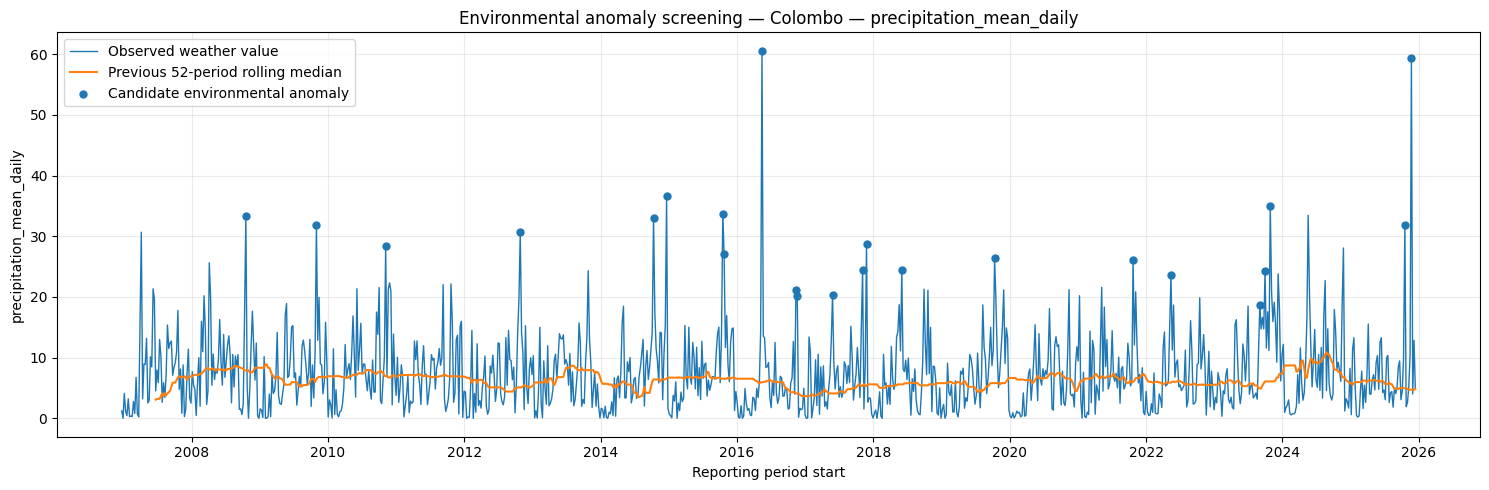

In [29]:
PLOT_FEATURE = "precipitation_mean_daily"
PLOT_DISTRICT = "colombo"

if PLOT_FEATURE not in weather_features:
    raise ValueError(f"{PLOT_FEATURE} is not available. Choose from: {weather_features}")

plot_data = environmental_scores[
    (environmental_scores["weather_feature"] == PLOT_FEATURE)
    & (environmental_scores["district_key"] == PLOT_DISTRICT)
].sort_values("week_start").copy()

if plot_data.empty:
    raise ValueError(f"No observations found for district: {PLOT_DISTRICT}")

plot_candidates = plot_data[
    plot_data["anomaly_status"].isin([
        "candidate_high_environmental_anomaly",
        "candidate_low_environmental_anomaly",
    ])
]

plt.figure(figsize=(15, 5))
plt.plot(plot_data["week_start"], plot_data["observed_value"],
         label="Observed weather value", linewidth=1)
plt.plot(plot_data["week_start"], plot_data["baseline_median"],
         label="Previous 52-period rolling median", linewidth=1.5)
plt.scatter(plot_candidates["week_start"], plot_candidates["observed_value"],
            label="Candidate environmental anomaly", s=25)
plt.title(f"Environmental anomaly screening — {PLOT_DISTRICT.title()} — {PLOT_FEATURE}")
plt.xlabel("Reporting period start")
plt.ylabel(PLOT_FEATURE)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 12. Compare candidate counts by district and weather feature

weather_feature,cloud_cover_mean,dew_point_2m_mean,et0_fao_evapotranspiration,precipitation_hours,precipitation_mean_daily,relative_humidity_2m_max,relative_humidity_2m_mean,relative_humidity_2m_min,shortwave_radiation_mean_daily,temperature_2m_max,temperature_2m_mean,temperature_2m_min,wind_speed_10m_max,wind_speed_10m_mean
district_key,,,,,,,,,,,,,,
ampara,5,13,2,50,102,1,0,0,18,0,0,0,0,1
anuradhapura,6,41,2,52,133,3,1,7,13,1,0,4,0,0
badulla,15,7,0,16,78,99,4,2,15,4,0,1,5,6
batticaloa,7,9,0,57,106,141,22,0,18,0,0,0,21,28
colombo,7,46,2,0,23,32,84,54,3,2,6,2,0,4
galle,6,13,3,0,18,23,32,11,6,2,11,3,3,21
gampaha,20,67,2,0,27,44,110,56,4,17,9,6,0,0
hambantota,5,27,4,30,134,0,0,3,17,4,1,1,0,0
jaffna,0,35,8,55,162,52,26,12,1,0,0,0,0,1


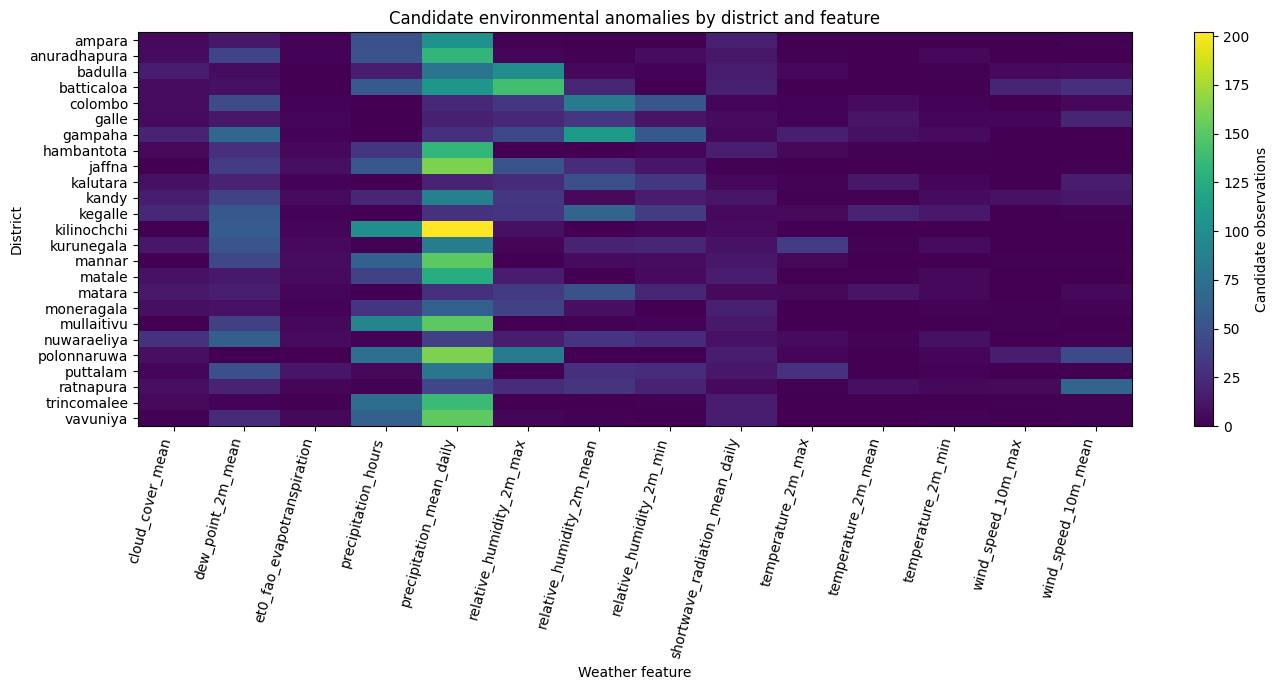

In [31]:
candidate_counts = (
    candidate_environmental_anomalies
    .groupby(["district_key", "weather_feature"])
    .size()
    .unstack(fill_value=0)
)
display(candidate_counts)

plt.figure(figsize=(14, 7))
plt.imshow(candidate_counts.values, aspect="auto")
plt.colorbar(label="Candidate observations")
plt.xticks(range(len(candidate_counts.columns)), candidate_counts.columns,
           rotation=75, ha="right")
plt.yticks(range(len(candidate_counts.index)), candidate_counts.index)
plt.title("Candidate environmental anomalies by district and feature")
plt.xlabel("Weather feature")
plt.ylabel("District")
plt.tight_layout()
plt.show()

## 13. Export results and reproducibility manifest

In [33]:
scores_path = OUTPUT_DIR / "environmental_anomaly_scores_weekly.csv"
candidates_path = OUTPUT_DIR / "candidate_environmental_anomalies.csv"
manifest_path = OUTPUT_DIR / "environmental_anomaly_manifest.json"

environmental_scores.to_csv(scores_path, index=False)
candidate_environmental_anomalies.to_csv(candidates_path, index=False)

manifest = {
    "project": "RiskWeave",
    "notebook": "08_environmental_anomaly_detection.ipynb",
    "input_file": str(DATA_PATH),
    "weather_data_source": "Open-Meteo ERA5 (as currently used in the project)",
    "rows_in_source_dataset": int(len(df)),
    "district_count": int(df["district_key"].nunique()),
    "date_start": str(df["week_start"].min().date()),
    "date_end": str(df["week_start"].max().date()),
    "weather_features_used": weather_features,
    "rolling_window_reporting_periods": ROLLING_WINDOW,
    "minimum_baseline_observations": MIN_BASELINE_OBSERVATIONS,
    "provisional_absolute_robust_score_threshold": PROVISIONAL_ABS_SCORE_THRESHOLD,
    "baseline_excludes_current_observation": True,
    "score_formula": "(observed_value - baseline_median) / (1.4826 * baseline_MAD)",
    "zero_or_missing_mad_scores": "Not scored; retained as unavailable",
    "interpretation": "Candidate unusual environmental observations only; not a dengue outbreak prediction or confirmation."
}
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=4)

print("Files saved:")
print(scores_path)
print(candidates_path)
print(manifest_path)

Files saved:
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\environmental_anomaly_detection\environmental_anomaly_scores_weekly.csv
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\environmental_anomaly_detection\candidate_environmental_anomalies.csv
c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\environmental_anomaly_detection\environmental_anomaly_manifest.json


In [34]:
# Final export verification

import os
import pandas as pd
import json

output_dir = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "environmental_anomaly_detection"
)

scores_path = os.path.join(
    output_dir,
    "environmental_anomaly_scores_weekly.csv"
)

candidates_path = os.path.join(
    output_dir,
    "candidate_environmental_anomalies.csv"
)

manifest_path = os.path.join(
    output_dir,
    "environmental_anomaly_manifest.json"
)

# Check files exist
for path in [scores_path, candidates_path, manifest_path]:
    print(os.path.basename(path), ":", os.path.exists(path))

# Load exported files
exported_scores = pd.read_csv(scores_path)
exported_candidates = pd.read_csv(candidates_path)

print("\nExported score table shape:")
print(exported_scores.shape)

print("\nExported candidate table shape:")
print(exported_candidates.shape)

print("\nCandidate status counts:")
print(exported_candidates["anomaly_status"].value_counts())

# Check manifest
with open(manifest_path, "r") as file:
    manifest = json.load(file)

print("\nManifest contents:")
print(json.dumps(manifest, indent=4))

environmental_anomaly_scores_weekly.csv : True
candidate_environmental_anomalies.csv : True
environmental_anomaly_manifest.json : True

Exported score table shape:
(346850, 9)

Exported candidate table shape:
(6704, 10)

Candidate status counts:
anomaly_status
candidate_high_environmental_anomaly    3666
candidate_low_environmental_anomaly     3038
Name: count, dtype: int64

Manifest contents:
{
    "project": "RiskWeave",
    "notebook": "08_environmental_anomaly_detection.ipynb",
    "input_file": "c:\\Users\\Nethmi\\Documents\\GitHub\\RiskWeave\\data\\processed\\dengue_weather_weekly_25_districts.csv",
    "weather_data_source": "Open-Meteo ERA5 (as currently used in the project)",
    "rows_in_source_dataset": 24775,
    "district_count": 25,
    "date_start": "2006-12-23",
    "date_end": "2025-12-13",
    "weather_features_used": [
        "precipitation_mean_daily",
        "precipitation_hours",
        "temperature_2m_mean",
        "temperature_2m_max",
        "temperature_2

## 14. Limitations and next validation tasks

Before operational use, environmental anomaly outputs need further review:

1. **Baseline sensitivity:** Investigate small and zero MAD values. Do not replace them with an arbitrary constant.
2. **Seasonality:** Compare the trailing baseline with district-specific seasonally matched baselines using historical observations only.
3. **Threshold validation:** Evaluate alternative thresholds and resulting candidate counts. A threshold is not an official warning criterion.
4. **Weather-data quality:** Review variable definitions, units, aggregation methods, missingness and source coverage.
5. **Spatial interpretation:** Compare district-specific patterns; national aggregation may hide local differences.
6. **Epidemiological interpretation:** Environmental anomalies are not dengue outbreaks. Any relationship with dengue must be investigated separately and with appropriate time lags.
7. **Data-source documentation:** Record that the current historical weather source is Open-Meteo ERA5, while the proposal identifies NASA POWER.

### Completion checklist
- [ ] Processed dataset loaded and paths verified
- [ ] Data-quality checks passed
- [ ] Available weather features reviewed
- [ ] Weather missingness and distributions inspected
- [ ] District-specific trailing baselines calculated
- [ ] Current observations excluded from their own baselines
- [ ] Candidate high and low environmental anomalies inspected
- [ ] District-level plots reviewed
- [ ] CSV outputs and manifest saved
- [ ] Limitations documented

**Do not describe environmental anomaly flags as confirmed dengue outbreaks.**